# Exercise 1 (10 points)

In this exercise, we will practice how to properly format code. You are given a simple but poorly formatted Python code snippet that performs some common data science tasks (loading data, cleaning, and basic analysis). Your task is to refactor the code to improve readability, organization, and adhere to Python's PEP8 formatting guidelines.

```
import pandas as pd 
import numpy as np

data=pd.read_csv('credit_risk_dataset.csv')
# drop rows with missing values
data=data.dropna()

cat_cols = ['person_home_ownership', 'loan_intent', 'loan_grade', 'cb_person_default_on_file']
def converting_datatypes(df, cat_cols, df_train=False):
    
    for col in cat_cols:
        df[col] = df[col].astype('category')
    
    df['person_age'] = df['person_age'].astype('int32')
    df['cb_person_cred_hist_length'] = df['cb_person_cred_hist_length'].astype('int32') 
    
    if df_train==True:

        df['loan_status'] = df['loan_status'].astype('int8')
        
    return df
        
data = converting_datatypes(data, cat_cols, df_train=True)

X=data.drop('loan_status',axis=1)
y=data['loan_status']

from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.3,random_state=42)

from sklearn.ensemble import HistGradientBoostingClassifier
hg=HistGradientBoostingClassifier(n_estimators=100, categorical_features='from_dtype')
hg.fit(X_train,y_train)
print('Train accuracy:',hg.score(X_train,y_train))
print('Test accuracy:',hg.score(X_test,y_test))
```

In [ ]:
import pandas as pd
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import train_test_split
 
 
def converting_datatypes(df, cat_cols, df_train=False):
    """Convert columns to the correct data types."""
    for col in cat_cols:
        df[col] = df[col].astype("category")
 
    df["person_age"] = df["person_age"].astype("int32")
    df["cb_person_cred_hist_length"] = df["cb_person_cred_hist_length"].astype("int32")
 
    if df_train:
        df["loan_status"] = df["loan_status"].astype("int8")
 
    return df
 
 
# Load the data
data = pd.read_csv("credit_risk_dataset.csv")
 
# Drop rows with missing values
data = data.dropna()
 
# Convert data types
cat_cols = [
    "person_home_ownership",
    "loan_intent",
    "loan_grade",
    "cb_person_default_on_file",
]
data = converting_datatypes(data, cat_cols, df_train=True)
 
# Split into features and target
X = data.drop("loan_status", axis=1)
y = data["loan_status"]
 
# Split into train and test sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42
)
 
# Train the model
hg = HistGradientBoostingClassifier(max_iter=100, categorical_features="from_dtype")
hg.fit(X_train, y_train)
 
# Print the results
print("Train accuracy:", hg.score(X_train, y_train))
print("Test accuracy:", hg.score(X_test, y_test))

# Exercise 2

In this exercise, we will practice data visualiation with the `credit_risk_dataset.csv` data file.

### Exercise 2(a) (2 points)

Load `pandas`, `matplotlib`, and `seaborn`.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

### Exercise 2(b) (2 points)

Read the `credit_risk_dataset.csv` data file and create a data frame called `credit`.

In [5]:
credit = pd.read_csv("credit_risk_dataset.csv")
display(credit)



,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4
...,...,...,...,...,...,...,...,...,...,...,...,...
32576,57,53000,MORTGAGE,1.0,PERSONAL,C,5800,13.16,0,0.11,N,30
32577,54,120000,MORTGAGE,4.0,PERSONAL,A,17625,7.49,0,0.15,N,19
32578,65,76000,RENT,3.0,HOMEIMPROVEMENT,B,35000,10.99,1,0.46,N,28
32579,56,150000,MORTGAGE,5.0,PERSONAL,B,15000,11.48,0,0.10,N,26


### Exercise 2(c) (4 points)

Create a histogram of `person_income`. Color the distribution based on `loan_status`. Comment on the shape of the distributions.

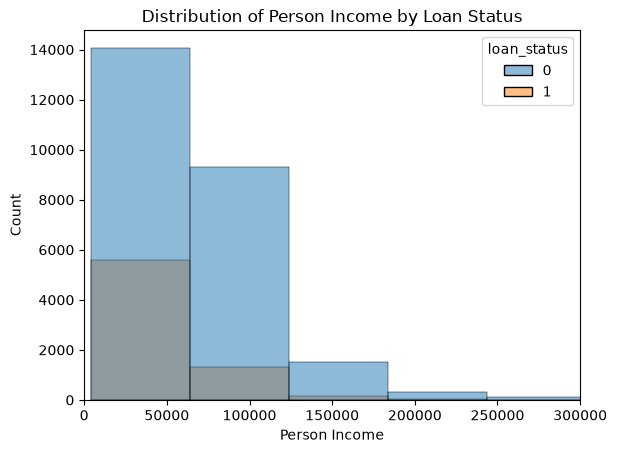

Both distributions are strongly right-skewed: most incomes are bunched at the
lower end, with a long tail of a few very high incomes. Borrowers who did not
default (loan_status = 0) are the larger group, and their distribution is
centered at a higher income (median about $60,000) with a much longer tail.


In [10]:
import textwrap

# Histogram of person_income, colored by loan_status
sns.histplot(data=credit, x="person_income", hue="loan_status", bins=100)
plt.xlim(0, 300000)   # zoom in; a few very large incomes stretch the axis
plt.title("Distribution of Person Income by Loan Status")
plt.xlabel("Person Income")
plt.ylabel("Count")
plt.show()

# Comment on the shape of the distributions (written as one long string)
comment = ("Both distributions are strongly right-skewed: most incomes are bunched "
           "at the lower end, with a long tail of a few very high incomes. "
           "Borrowers who did not default (loan_status = 0) are the larger group, and their "
           "distribution is centered at a higher income (median about $60,000) with a much "
           "longer tail. ")

# Wrap the text to 80 characters per line and print it
print(textwrap.fill(comment, width=80))

### Exercise 2(d) (5 points)

Create a side-by-side boxplot of `loan_int_rate` based on `loan_grade`. Describe the chart.

### Exercise 2(e) (10 points)

Is there a realtionship between `person_home_ownership`, `loan_intent`, and `loan_status`? Create a heatmap that shows the average `loan_status` based on `person_home_ownership` and `loan_intent`. Describe the chart.

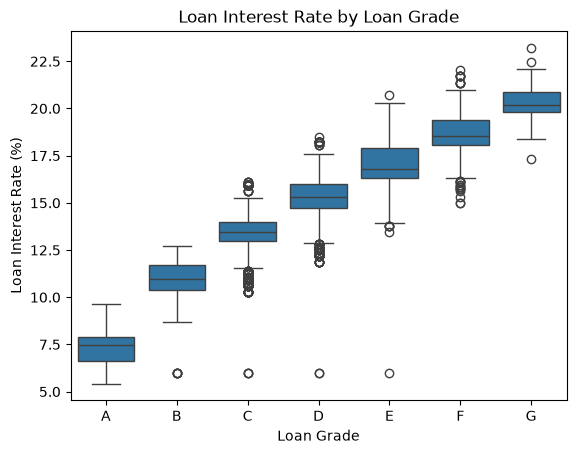

Interest rates rise steadily from grade A to grade G, from a median of about
7.5% to about 20%. Each grade has a fairly narrow range, and grades B through E
show some low outliers.


In [12]:
# Side-by-side boxplot of loan_int_rate by loan_grade
sns.boxplot(data=credit, x="loan_grade", y="loan_int_rate",
            order=["A", "B", "C", "D", "E", "F", "G"])
plt.title("Loan Interest Rate by Loan Grade")
plt.xlabel("Loan Grade")
plt.ylabel("Loan Interest Rate (%)")
plt.show()

# Describe the chart
comment = ("Interest rates rise steadily from grade A to grade G, from a median of "
           "about 7.5% to about 20%. Each grade has a fairly narrow range, and grades "
           "B through E show some low outliers.")

print(textwrap.fill(comment, width=80))

# Exercise 3 (10 points)

In this exercise, we will practice import formatting (Section 6.2 of Chapter 6).

### Exercise 3(a) (5 points)

The import block below grew organically and does not follow PEP8. Rewrite it so that:

- imports are grouped as (1) standard library, (2) third-party libraries, with a blank line between groups,
- imports are sorted alphabetically within each group (`import x` statements before `from x import y` statements),
- there is only one import per module line (for example, `import sys, os` must be split), and
- repeated imports from the same module are merged into a single line.


In [6]:
import time
from sklearn.metrics import accuracy_score

import sys, os
import numpy as np
from sklearn.model_selection import train_test_split
import pandas as pd

from sklearn.ensemble import HistGradientBoostingClassifier
import matplotlib.pyplot as plt

from sklearn.metrics import roc_auc_score, f1_score

In [13]:
import os
import sys
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score
from sklearn.model_selection import train_test_split

### Exercise 3(b) (5 points)

Name two cases where reordering imports (for example, with `isort`) is **not** behavior-preserving. How can you tell `isort` to leave a line alone?

**Order-dependent imports.** Some imports must run after a setup step. For example, the Matplotlib backend must be set with `matplotlib.use("Agg")` before `matplotlib.pyplot` is imported. Sorting alphabetically can move the `pyplot` import ahead of that line.

**Registration imports.** Some libraries are imported only for their side effect, such as registering a plugin or an accessor. Because the name is never used directly, a linter flags it as unused and may offer to delete it, which silently breaks the feature.

**How to tell isort to leave a line alone**
- Add `# isort: skip` to the end of the individual line.
- Wrap a block of lines between `# isort: off` and `# isort: on`.